<a href="https://colab.research.google.com/github/profecarlosrico/An-lisis_ConnectaTel/blob/main/S7_Version_Estudiante_Project_ConnectaTel_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
plans = pd.read_csv('/content/plans.csv')
users = pd.read_csv('/content/users_latam.csv')
usage = pd.read_csv('/content/usage.csv')

In [ ]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head()
#City con ?, diferente nomenclatura y nombre

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 260.0+ bytes


In [ ]:
users.info()
#plan, churn_date aparecen con tipo object y debe ser date
#city tiene solo 3531 registros no 4000 hay faltantes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()
#date aparece como object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64


In [ ]:
print(usage.isna().sum())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint: La columna city en el dataset users presenta 469 nulos.  
* Hint: La columna churn_date presenta 3534 NaN que equivale a los usuarios activos.

 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
- city  Reemplazar por NaN. Por lo que no representa ningún error ni problema.Y se hace necesaria su revisión pues presentan sentinels, diferencias entre código de ciudad o nombre de ciudad.
- En la columna churn_date no es necesaria alguan acción puesto que ya están registrados y son los usuarios activos.

### 2.2 Detección de valores inválidos y sentinels

**Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000



- - Las columnas `user_id` aprece de tipo int64 no es necesario realizar procesos estadísticos pues es un código único
- La columna `age` presenta un valor mínimo de -999 lo que se puede interpretar como un sentinel


In [ ]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` aprecen de tipo int64 no es necesario realizar procesos estadísticos pues es un código único
- Las columnas duration	y length presentan valores máximos que se hace necesario revisar.

In [ ]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].describe())
    print("")


count       3531
unique         7
top       Bogotá
freq         808
Name: city, dtype: object

count       4000
unique         2
top       Basico
freq        2595
Name: plan, dtype: object



- La columna `city` tiene valores faltantes. Hay 7 ciudades a tener en cuenta. La más frecuente es Bogotá
- La columna `plan` es coherente con los planes presentes.

In [ ]:
# explorar columna categórica de usage
usage['type'].describe()

,type
count,40000
unique,2
top,text
freq,22092


- La columna `type`es coherente con los tipos de texto o llamada.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- En la columna city.
- ¿Qué acción tomarías?
- reemplazar los vacíos por Nan.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
display(users.head())
display(users.info())

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   int64         
 4   city        3531 non-null   object        
 5   reg_date    4000 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 250.1+ KB


None

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
display(usage.info())
display(usage.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   id        40000 non-null  int64         
 1   user_id   40000 non-null  int64         
 2   type      40000 non-null  object        
 3   date      39950 non-null  datetime64[ns]
 4   duration  17924 non-null  float64       
 5   length    22104 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.8+ MB


None

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.unique())

[2022 2026 2023 2024]


En `reg_date`, aparecen los años 2022, 2023 y 2024 que son los esperados. 2026 esta fuera del rango de análisis.

In [ ]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.unique())

[2024.   nan]


En `date`, aparece el año 2024 como rango de uso del servicio y NaN correspondiente a fechas con error o no válidas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? Sí, el año 2026, que para la fecha del proyecto es un valor futuro.
- ¿Qué harías con ellas? Convertirlos a NaN
- En usage, no aparecen años fuera de rango, pero sí surgieron valores nulos (NaN) al convertir date, lo que indica fechas con formato inválido en el dato original. Decidí dejarlos así, ya que el registro sigue aportando información de consumo (duración, mensajes o datos) aunque no se conozca la fecha exacta.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)
# Verificar cambios
print(users["age"].describe().round(2))
print(age_mediana)

count    4000.00
mean       48.12
std        17.69
min        18.00
25%        33.00
50%        47.00
75%        63.00
max        79.00
Name: age, dtype: float64
47.0


In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)
# Verificar cambios
users['city'].isna().sum()

np.int64(565)

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year == 2026, ['reg_date']]= pd.NaT
# Verificar cambios
print(users['reg_date'].dt.year.unique())


[2022.   nan 2023. 2024.]


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
solo_duration = usage['duration'].notna() & usage['length'].isna()
solo_length = usage['duration'].isna() & usage['length'].notna()
ambos_nulos = usage['duration'].isna() & usage['length'].isna()

print("Nulos en llamadas", solo_duration.sum())
print("Ambos nulos", ambos_nulos.sum())

print("Nulos en llamadas", usage.groupby('type')['duration'].apply(lambda x: x.isna().sum()))


Nulos en llamadas 17896
Ambos nulos 0
Nulos en llamadas type
call        0
text    22076
Name: duration, dtype: int64


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
print("Nulos en mensajes", solo_length.sum())
print(ambos_nulos.sum())
print("Nulos en mensajes", usage.groupby('type')['length'].apply(lambda x: x.isna().sum()))

Nulos en mensajes 22076
0
Nulos en mensajes type
call    17896
text        0
Name: length, dtype: int64


Los nulos en `duration` y `length` se explican por el tipo de uso del plan contratado ("Text"/"Call") por el usuario. Cuando se usa "Text" la columna [duration] aparace nulo y vicersa, cuando el tipo es "Call" la columna [length] es la que aparece en nulo. Es un tipo MAR(Missing At Random) entre ambas columnas. Esto se evidencia con 17896 nulos en duration cuando type=='text', 22076 nulos en length cuando type=='call', y 0 casos con ambos nulos a la vez.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(cant_mensajes=('is_text','sum'), cant_llamadas=('is_call','sum'),cant_minutos_llamadas=('duration','sum'))

# observar resultado
usage_agg.head(3)

,cant_mensajes,cant_llamadas,cant_minutos_llamadas
user_id,,,
10000,7,3,23.70
10001,5,10,33.18
10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile =  users.merge(usage_agg, left_on='user_id', right_index=True)
print(user_profile.head(5))
print(users[~users['user_id'].isin(usage_agg.index)])

   user_id first_name last_name  age      city                      reg_date  \
0    10000     Carlos    Garcia   38  Medellín 2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53      <NA> 2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX 2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá 2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL 2022-01-02 02:17:11.657914478   

      plan churn_date  cant_mensajes  cant_llamadas  cant_minutos_llamadas  
0   Basico        NaN              7              3                  23.70  
1   Basico        NaN              5             10                  33.18  
2   Basico        NaN              5              2                  10.74  
3  Premium        NaN             11              3                   8.99  
4   Basico        NaN              4              3                   8.01  
      user_id first_name last_name  age  city            

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,reg_date,cant_mensajes,cant_llamadas,cant_minutos_llamadas
count,3999.000000,3999.000000,3959,3999.000000,3999.000000,3999.000000
mean,11999.729432,48.124531,2023-07-03 23:11:34.436427776,5.524381,4.478120,23.317054
min,10000.000000,18.000000,2022-01-01 00:00:00,0.000000,0.000000,0.000000
25%,10999.500000,33.000000,2022-10-02 18:38:37.179294720,4.000000,3.000000,11.120000
50%,12000.000000,47.000000,2023-07-04 13:17:14.358589696,5.000000,4.000000,19.780000
75%,12999.500000,63.000000,2024-04-03 05:38:39.879970048,7.000000,6.000000,31.415000
max,13999.000000,79.000000,2024-12-31 00:00:00,17.000000,15.000000,155.690000
std,1154.898108,17.692032,NaN,2.358416,2.144238,18.168095


In [ ]:
# Distribución porcentual del tipo de plan
(user_profile["plan"].value_counts(normalize=True)* 100).round(2)

,proportion
plan,
Basico,64.87
Premium,35.13


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

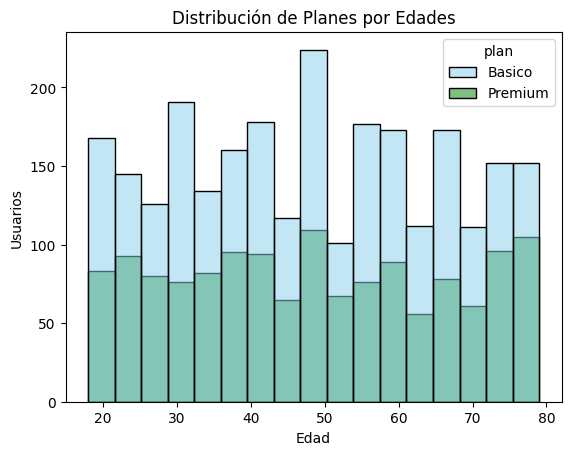

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,x='age',hue='plan',palette=['skyblue','green'])

# Etiquetas y título del gráfico
plt.xlabel('Edad')
plt.ylabel('Usuarios')
plt.title('Distribución de Planes por Edades')
plt.show()

💡Insights:
- Hay uniformidad o similitud en la distribución por edad, sin sesgo marcado. No hay un grupo etario en que se diferencie la preferencia por un plan Básico o Premium.

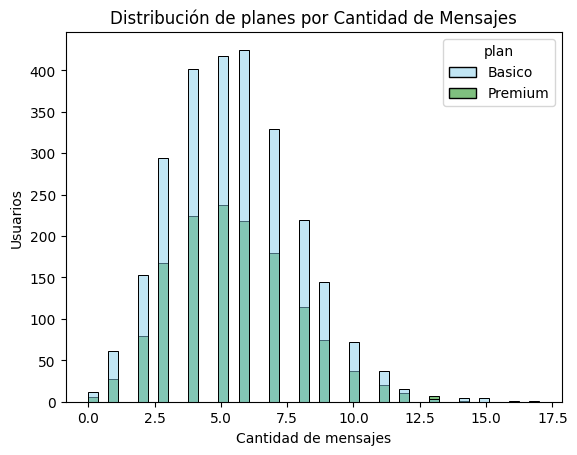

In [ ]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data=user_profile,x='cant_mensajes',hue='plan',palette=['skyblue','green'])

# Etiquetas y título del gráfico
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Usuarios')
plt.title('Distribución de planes por Cantidad de Mensajes')
plt.show()


💡Insights:
La distribución presenta un ligero sesgo a la derecha, muchos usuarios al rededor de 5 mensajes. Sin clara diferencia entre ambos planes, Básico y Premium.

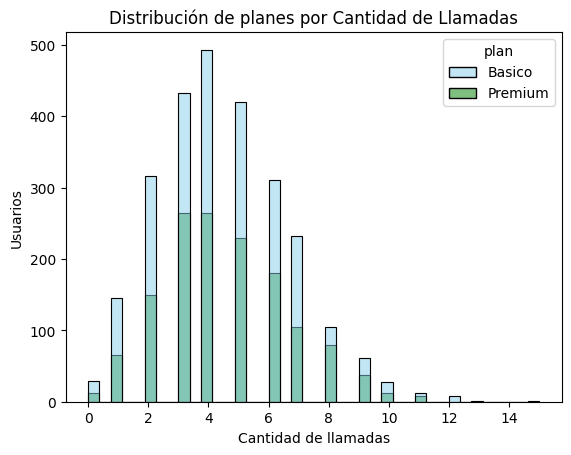

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile,x='cant_llamadas',hue='plan',palette=['skyblue','green'])

# Etiquetas y título del gráfico
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Usuarios')
plt.title('Distribución de planes por Cantidad de Llamadas')
plt.show()


💡Insights:
- La distribución presenta un ligero sesgo a la derecha, muchos usuarios al rededor de 4 llamadas. Sin clara diferencia entre ambos planes, Básico y Premium.

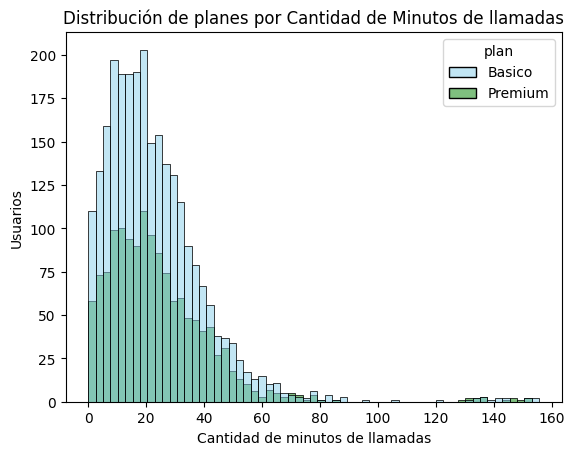

In [ ]:
# Histograma para visualizar la cant_minutos_llamadas
sns.histplot(data=user_profile,x='cant_minutos_llamadas',hue='plan',palette=['skyblue','green'])

# Etiquetas y título del gráfico
plt.xlabel('Cantidad de minutos de llamadas')
plt.ylabel('Usuarios')
plt.title('Distribución de planes por Cantidad de Minutos de llamadas')
plt.show()



💡Insights:
La distribución presenta un marcado sesgo a la derecha, muchos usuarios al rededor de 20 minutos por llamada. Sin clara diferencia entre ambos planes, Básico y Premium.


### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

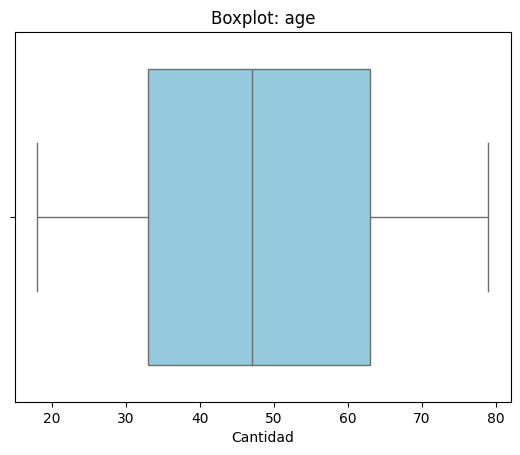

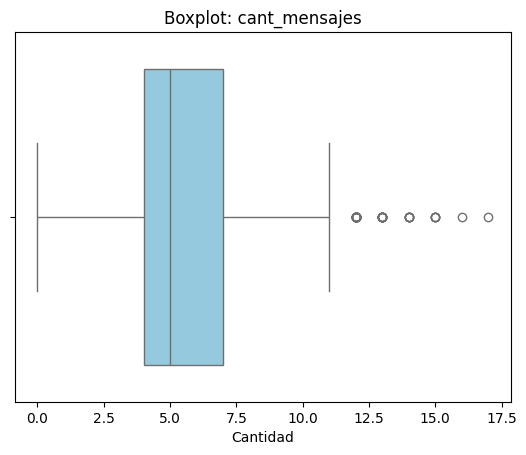

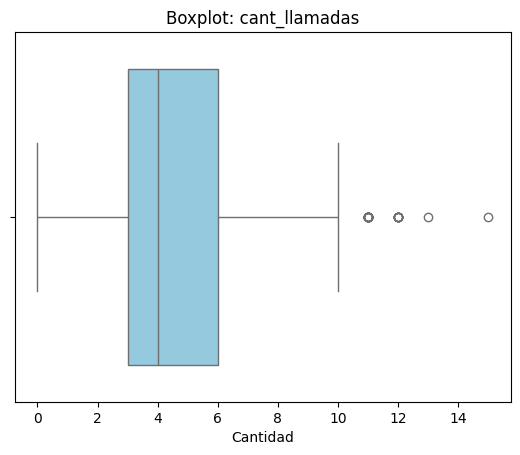

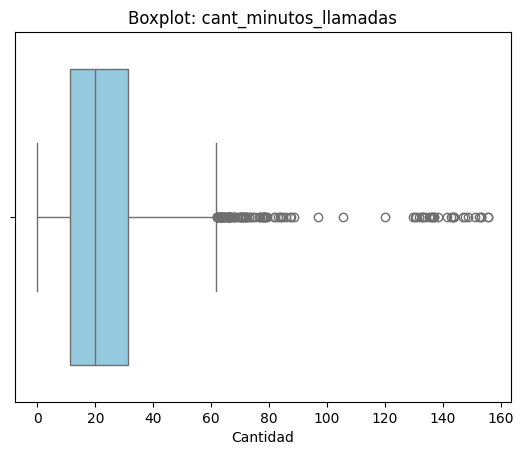

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue' )
    plt.xlabel('Cantidad')
    plt.title(f'Boxplot: {col}')
    plt.show()


# 💡Insights:
- Age: No presenta valores fuera de límite. Presenta un mínimo de 18 y un máximo de 79.
- cant_mensajes: presenta valores fuerade los bigotes del boxplot, lo que indica la presencia de outliers, mínimo en 0 y máximo en 17
- cant_llamadas: presenta valores fuera de los bigotes del boxplot, lo que indica la presencia de outliers, mínimo en 0 y máximo en 15
- cant_minutos_llamada: presenta un fuerte sesgo a la derecha con valores fuera de los bigotes del boxplot, lo que indica la presencia de outliers, la gran mayoría de los datos está entre 11 y 31 minutos y valor extremo máximo de 155

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']
columnas= ['user_id', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']
for col in columnas_limites:
    # calcular Q1, Q3 e IQR
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    # calcular límite inferior y superior
    limite_inferior =  Q1 - 1.5*IQR
    limite_superior =  Q3 + 1.5*IQR
    # Mostrar resultados
    print('Primer cuartil: ',col, Q1)
    print('Tercer cuartil: ',col, Q3)
    print('IQR: ',col, IQR)
    print("\nRegistros abajo del límite inferior", col)
    print(user_profile[columnas][ user_profile[col] < limite_inferior].sort_values(by=col, ascending=False))
    print("\nRegistros arriba del límite superior",col)
    print(user_profile[columnas][user_profile[col] > limite_superior].sort_values(by=col, ascending=False))
    outliers = user_profile.loc[(user_profile[col] < limite_inferior) | (user_profile[col] > limite_superior)]
    porcentaje_outliers = (len(outliers) /user_profile.shape[0] ) * 100

    print("\nPorcentaje de outliers en ", col, (porcentaje_outliers))
    print('')

Primer cuartil:  cant_mensajes 4.0
Tercer cuartil:  cant_mensajes 7.0
IQR:  cant_mensajes 3.0

Registros abajo del límite inferior cant_mensajes
Empty DataFrame
Columns: [user_id, cant_mensajes, cant_llamadas, cant_minutos_llamadas]
Index: []

Registros arriba del límite superior cant_mensajes
      user_id  cant_mensajes  cant_llamadas  cant_minutos_llamadas
1197    11197             17              3                  24.93
3819    13819             16             11                  47.80
2026    12026             15              3                   9.48
2676    12676             15              3                  24.98
1159    11159             15              2                   5.15
2302    12302             15              5                  23.26
3475    13475             14              7                  19.68
3772    13772             14              8                  38.59
3873    13873             14              4                  24.20
539     10539             14       

In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
print(user_profile[columnas_limites].describe())

       cant_mensajes  cant_llamadas  cant_minutos_llamadas
count    3999.000000    3999.000000            3999.000000
mean        5.524381       4.478120              23.317054
std         2.358416       2.144238              18.168095
min         0.000000       0.000000               0.000000
25%         4.000000       3.000000              11.120000
50%         5.000000       4.000000              19.780000
75%         7.000000       6.000000              31.415000
max        17.000000      15.000000             155.690000


💡Insights:
- cant_mensajes: recomiendo mantener los valores a pesar de ser outliers, por que son consumos posibles y eliminarlos sesgaría los análisis.
- cant_llamadas: recomiendo mantener los valores a pesar de ser outliers, por que son consumos posibles y eliminarlos sesgaría los análisis.
- cant_minutos_llamada: recomiendo mantener los valores a pesar de ser outliers, por que son consumos posibles y eliminarlos sesgaría los análisis.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_mensajes']<5) & (user_profile['cant_llamadas'] < 5),
    (user_profile['cant_mensajes']<10) & (user_profile['cant_llamadas'] < 10)
]
valores = ['Bajo uso', 'Uso medio']
user_profile['grupo_uso'] = np.select(condiciones, valores, default='Alto uso')

# Verificar cambios
print(user_profile['grupo_uso'].value_counts())

grupo_uso
Uso medio    2943
Bajo uso      778
Alto uso      278
Name: count, dtype: int64


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamadas,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
condiciones = [
    (user_profile['age']<30) ,
    (user_profile['age']<60)
]
valores = ['Joven', 'Adulto']
user_profile['grupo_edad'] = np.select(condiciones, valores, default='Adulto Mayor')

# Verificar cambios
print(user_profile['grupo_edad'].value_counts())
print((user_profile['grupo_edad'].value_counts(normalize=True) * 100).round(2))

(pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index') * 100).round(2)

grupo_edad
Adulto          2017
Adulto Mayor    1222
Joven            760
Name: count, dtype: int64
grupo_edad
Adulto          50.44
Adulto Mayor    30.56
Joven           19.00
Name: proportion, dtype: float64


grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,7.59,18.05,74.37
Adulto Mayor,6.06,21.03,72.91
Joven,6.71,20.66,72.63


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamadas,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

/tmp/ipykernel_2112/1538061959.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=user_profile,x='grupo_uso',palette=['skyblue'])
/tmp/ipykernel_2112/1538061959.py:2: UserWarning: 
The palette list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(data=user_profile,x='grupo_uso',palette=['skyblue'])


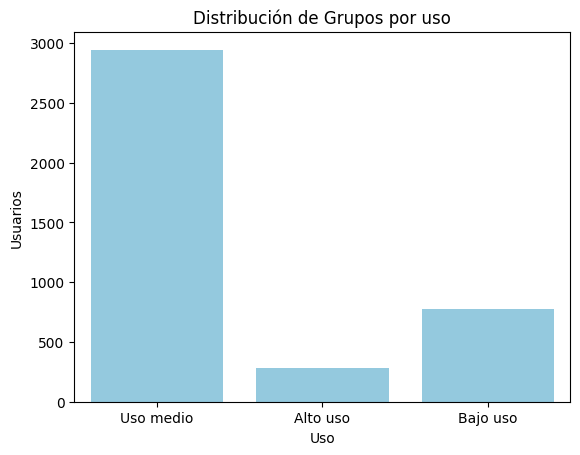

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile,x='grupo_uso',palette=['skyblue'])

# Etiquetas y título del gráfico
plt.xlabel('Uso')
plt.ylabel('Usuarios')
plt.title('Distribución de Grupos por uso')
plt.show()

/tmp/ipykernel_2112/384657795.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=user_profile,x='grupo_edad',palette=['skyblue'])
/tmp/ipykernel_2112/384657795.py:2: UserWarning: 
The palette list has fewer values (1) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.countplot(data=user_profile,x='grupo_edad',palette=['skyblue'])


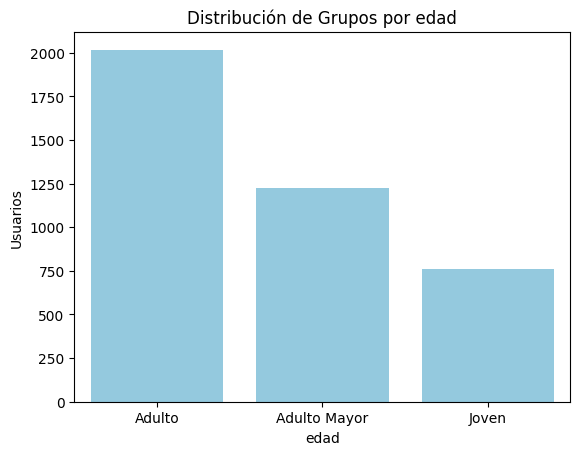

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile,x='grupo_edad',palette=['skyblue'])

# Etiquetas y título del gráfico
plt.xlabel('edad')
plt.ylabel('Usuarios')
plt.title('Distribución de Grupos por edad')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- En el dataset 'users', la columna 'city' presenta 469 valores nulos equivalentes ~11.7%, el signo "?" que podría ser un sentinel.
- En el dataset 'users', la columna 'age' tiene el valor -999 que puede ser un sentinel.
- En el dataset 'usage' las columnas duration y length presentan valores máximos que se hace necesario revisar, como posibles outliers y los nulos MAR deben ser atendidos.
- En el dataset 'users' la columna 'reg_date' tiene el valor 2026 fuera de rango, como fecha futura.
- El tipo de dato de 'users.reg_date' y 'usage_date' es necesario convertir de object a date para poder realizar la segmentación.
- La columna 'users.churn_date' tiene 466/3999 no nulos equivalentes a los usuarios que han cancelado el plan.
- Se identificó un usuario (user_id 11082) sin registros de uso (llamadas, mensajes o datos), por lo que fue excluido del análisis de perfil de uso al hacer la unión con la tabla usage. Esto representa un caso de usuario inactivo o recién registrado sin consumo aún.

🔍 **Segmentos por Edad**
- Hay uniformidad o similitud en la distribución por edad, sin sesgo marcado.
- Presentan una distribución uniforme entre los 18 y 79 años con una media de 47 años.
- Con una distribución entre Adulto: 2017/50.44%, Adulto Mayor: 1222/30.56%, Joven: 760/19.00%.
- No hay un grupo etario en que se diferencie la preferencia por un plan Básico o Premium.
  
📊 **Segmentos por Nivel de Uso**
Los tres grupos de edad tienen una distribución de uso muy parecida: alrededor de 72-74% en uso medio, 18-21% en bajo uso, y solo 6-8% en alto uso. Las diferencias entre grupos son pequeñas (unos pocos puntos porcentuales).

➡️ Esto sugiere que el segmento Adulto se convierte en el más valioso para la compañía.

💡 **Recomendaciones**
- Estandarizar 'users.city' al codigo internacional de ciudad, pues aparecen registros con 'Medellín', 'Bogotá' que a la hora de analizar la columna ciudad frente al uso, edades, etc se podría dificultar.

- Los valores altos de consumo (hasta 155 minutos) indican que hay un segmento de ususarios a los que se le puede ofrecer un plan diferenciado frente a un tope máximo del plan.

-  ConnectaTel  puede dirigir futuras campañas comerciales hacia el segmento de población adulta alrededor de los 45-50 años que es el segmento con mayor número de población y consumo estable, como segmento con mejores ingresos, con reconocimiento y posición social.

- Teniendo en cuenta que la edad/consumo que el consumo medio es muy similar (Adulto 74.37 Adulto Mayor 72.91 Joven 72.63) las campañas de marketing deben enfocarse a valorar el aumento del consumo con descuentos o promociones.

- Podría incluirse la variable género para enlazarla con las ya mensionadas de nivel de edad y consumo.

- Se detectó que solo el 0.12% de los usuarios presenta un consumo de minutos de llamada considerado atípico (outlier), con valores de hasta 155 minutos. Aunque es un grupo muy pequeño, estos casos podrían representar clientes con necesidades de consumo superiores al plan actual, lo que abre una oportunidad de ofrecerles un plan premium o paquete adicional en vez de perderlos por insatisfacción.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: [S7_Version_Estudiante_Project_ConnectaTel_Final.ipynb](https://github.com/profecarlosrico/An-lisis_ConnectaTel.git)